# Vehicle Damage Classification Using Deep Learning

**Student:** Anjali Tummala  
**Course:** COMP-671 Deep Learning  
**University:** Rivier University

## Project Objective

The goal of this project is to investigate how well deep learning
models can classify different types of vehicle damage from images.

The project compares a baseline convolutional neural network (CNN)
with a transfer-learning model. It also investigates whether image
data augmentation improves the model's ability to generalize to
unseen vehicle images.

## Research Questions

1. Can a transfer-learning model outperform a basic CNN for vehicle
   damage image classification?

2. Does image data augmentation improve generalization and reduce
   overfitting?

## Experimental Plan

The project will be completed in four main stages:

1. Explore and preprocess the vehicle damage image dataset.
2. Train a basic CNN as the baseline model.
3. Train a pretrained residual network using transfer learning.
4. Compare the models and study the effect of data augmentation.

The models will be evaluated on held-out data using accuracy,
precision, recall, F1-score, and a confusion matrix. Incorrect
predictions will also be examined to understand common failure cases.

In [ ]:
# Basic libraries for the project
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Deep learning
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


## 2. Dataset and Data Exploration

This section examines the vehicle damage image dataset before model
training. The goal is to understand the available damage categories,
number of images, class distribution, and image characteristics.

Exploring the dataset before training is important because class
imbalance, image quality, and variation between categories can affect
model performance.

In [1]:
import os
import zipfile

zip_path = "/content/archive.zip"
extract_path = "/content/vehicle_damage_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files:", os.listdir(extract_path))


Dataset extracted successfully!
Files: ['image', 'data.csv']


In [2]:

import pandas as pd
import os

data_path = "/content/vehicle_damage_data"

# Load the dataset information
df = pd.read_csv(os.path.join(data_path, "data.csv"))

# Display basic information
print("Total rows:", len(df))
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDamage category counts:")
print(df["classes"].value_counts(dropna=False))

# Count actual image files
image_path = os.path.join(data_path, "image")
image_files = [
    f for f in os.listdir(image_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("\nTotal image files:", len(image_files))


Total rows: 1594

Column names:
['Unnamed: 0', 'image', 'classes']

First 5 rows:


,Unnamed: 0,image,classes
0,0,image/0.jpeg,unknown
1,1,image/1.jpeg,head_lamp
2,2,image/2.jpeg,door_scratch
3,3,image/3.jpeg,head_lamp
4,4,image/4.jpeg,unknown



Damage category counts:
classes
unknown           549
door_dent         192
bumper_scratch    164
door_scratch      154
glass_shatter     137
tail_lamp         136
head_lamp         133
bumper_dent       129
Name: count, dtype: int64

Total image files: 1512


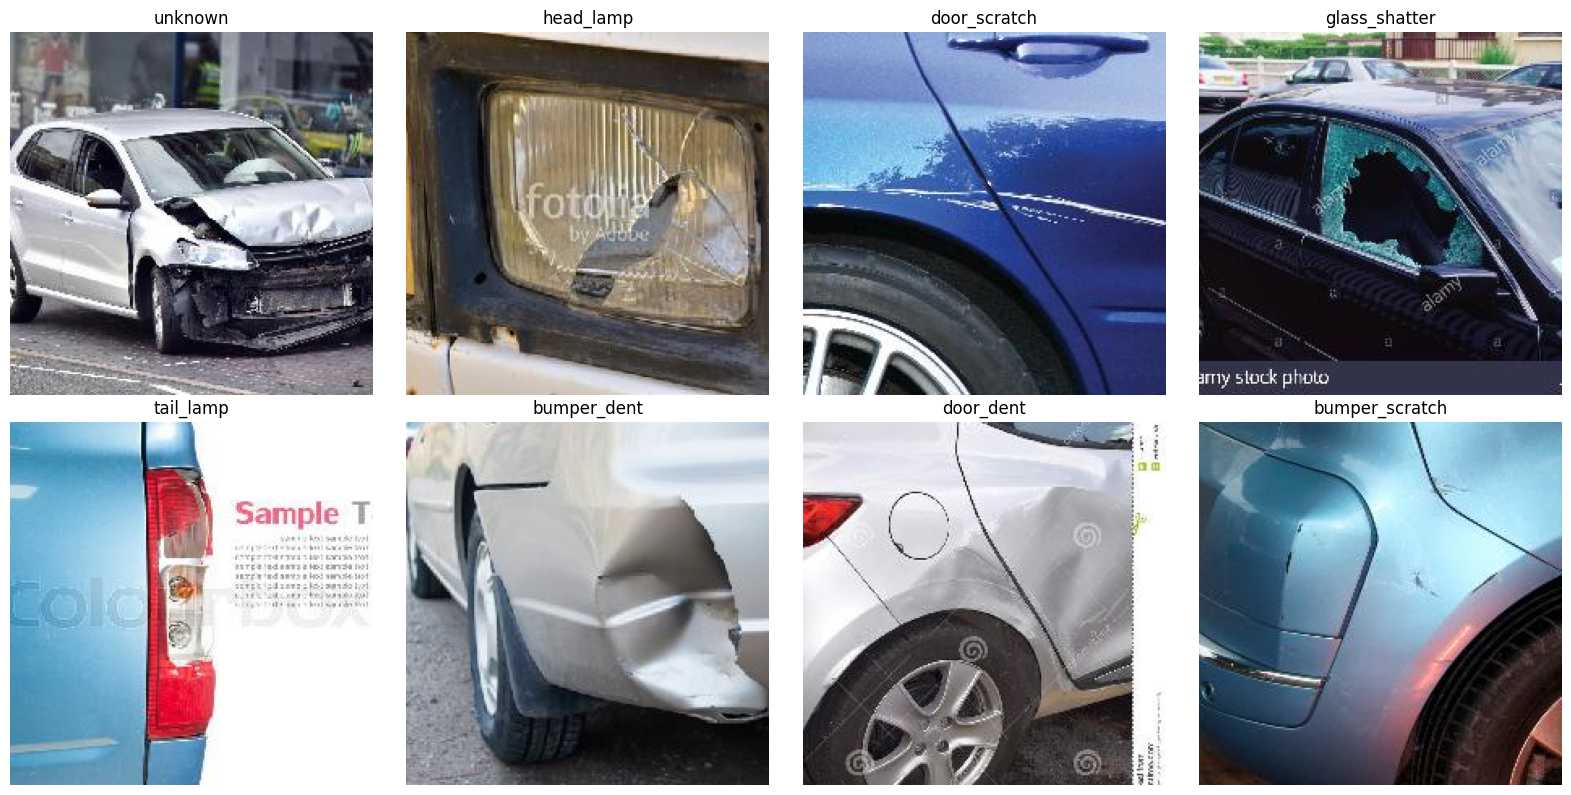

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import os

data_path = "/content/vehicle_damage_data"

# Display one image from each category
categories = df["classes"].dropna().unique()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, category in zip(axes.flat, categories):
    rows = df[df["classes"] == category]

    for _, row in rows.iterrows():
        image_file = os.path.join(data_path, row["image"])

        if os.path.isfile(image_file):
            img = Image.open(image_file).convert("RGB")
            ax.imshow(img)
            ax.set_title(category)
            break

    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:

import os
import pandas as pd

data_path = "/content/vehicle_damage_data"

# Create a working copy without changing the original CSV
clean_df = df.copy()

# Remove rows without an image name or category
clean_df = clean_df.dropna(subset=["image", "classes"])

# Check whether each image exists
clean_df["full_path"] = clean_df["image"].apply(
    lambda name: os.path.join(data_path, str(name))
)

clean_df["file_exists"] = clean_df["full_path"].apply(
    os.path.isfile
)

print("Original CSV records:", len(df))
print("Records with existing images:", clean_df["file_exists"].sum())
print("Records with missing images:", (~clean_df["file_exists"]).sum())

# Keep only records with actual image files
clean_df = clean_df[clean_df["file_exists"]].copy()

# Remove duplicate image paths
before = len(clean_df)
clean_df = clean_df.drop_duplicates(subset=["image"])

print("Duplicate image records removed:", before - len(clean_df))
print("Final usable records:", len(clean_df))

print("\nUsable images by category:")
print(clean_df["classes"].value_counts())


Original CSV records: 1594
Records with existing images: 1594
Records with missing images: 0
Duplicate image records removed: 82
Final usable records: 1512

Usable images by category:
classes
unknown           549
door_dent         192
door_scratch      154
glass_shatter     137
tail_lamp         136
head_lamp         133
bumper_dent       129
bumper_scratch     82
Name: count, dtype: int64


In [5]:

# Check whether any image has conflicting labels
label_counts = df.groupby("image")["classes"].nunique()

conflicting_images = label_counts[label_counts > 1]

print("Images with conflicting labels:", len(conflicting_images))

if len(conflicting_images) > 0:
    print("\nExamples of conflicting labels:")
    display(
        df[df["image"].isin(conflicting_images.index)]
        .sort_values("image")
        .head(20)
    )
else:
    print("No conflicting labels found.")

# Check the labels associated with duplicate image records
duplicate_rows = df[df.duplicated("image", keep=False)]

print("\nDuplicate records by category:")
print(duplicate_rows["classes"].value_counts())


Images with conflicting labels: 0
No conflicting labels found.

Duplicate records by category:
classes
bumper_scratch    164
Name: count, dtype: int64


In [6]:

from sklearn.model_selection import train_test_split

# Keep the seven specific damage categories
model_df = clean_df[
    clean_df["classes"] != "unknown"
].copy()

# First split: 70% training, 30% remaining
train_df, temp_df = train_test_split(
    model_df,
    test_size=0.30,
    random_state=42,
    stratify=model_df["classes"]
)

# Split the remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["classes"]
)

print("Total labeled images:", len(model_df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining category counts:")
print(train_df["classes"].value_counts())

print("\nValidation category counts:")
print(val_df["classes"].value_counts())

print("\nTesting category counts:")
print(test_df["classes"].value_counts())

# Verify there is no image overlap between splits
train_images = set(train_df["image"])
val_images = set(val_df["image"])
test_images = set(test_df["image"])

assert train_images.isdisjoint(val_images)
assert train_images.isdisjoint(test_images)
assert val_images.isdisjoint(test_images)

print("\nSuccess: No image filenames overlap between splits!")

# Save splits for reproducibility
train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)


Total labeled images: 963
Training images: 674
Validation images: 144
Testing images: 145

Training category counts:
classes
door_dent         134
door_scratch      108
glass_shatter      96
tail_lamp          95
head_lamp          93
bumper_dent        90
bumper_scratch     58
Name: count, dtype: int64

Validation category counts:
classes
door_dent         29
door_scratch      23
head_lamp         20
glass_shatter     20
bumper_dent       20
tail_lamp         20
bumper_scratch    12
Name: count, dtype: int64

Testing category counts:
classes
door_dent         29
door_scratch      23
tail_lamp         21
glass_shatter     21
head_lamp         20
bumper_dent       19
bumper_scratch    12
Name: count, dtype: int64

Success: No image filenames overlap between splits!


In [7]:

import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# Use the same class order for all datasets and models
class_names = sorted(model_df["classes"].unique())
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

print("Class names:", class_names)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["full_path"].astype(str).tolist()
    labels = [
        class_to_index[name]
        for name in dataframe["classes"]
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

print("Datasets prepared successfully!")


Class names: ['bumper_dent', 'bumper_scratch', 'door_dent', 'door_scratch', 'glass_shatter', 'head_lamp', 'tail_lamp']
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Pixel value range: 0.0 255.0
Datasets prepared successfully!


#Step 1 — Build the baseline CNN
A CNN (Convolutional Neural Network) learns visual patterns from images, such as scratches, dents, and broken glass.
We will train this simple CNN first so we can compare its results with ResNet50 later.

In [1]:


import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

tf.keras.utils.set_random_seed(42)

# Load pretrained ResNet50
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Build the model
inputs = layers.Input(shape=(224, 224, 3))

# ResNet50 preprocessing:
# RGB to BGR and ImageNet mean subtraction
x = layers.Rescaling(
    scale=1.0,
    offset=0.0
)(inputs)

# RGB -> BGR using channel reversal
x = layers.Lambda(
    lambda image: tf.reverse(image, axis=[-1])
)(x)

# ImageNet channel mean subtraction
x = layers.Rescaling(
    scale=1.0,
    offset=-103.939
)(x)

# Adjust the remaining channel means
# using a serializable normalization layer
# (BGR means: 103.939, 116.779, 123.68)



94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [9]:

# Train the baseline CNN
history_cnn = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

# Save the trained model
baseline_cnn.save(
    "/content/baseline_cnn.keras"
)

print("Baseline CNN training completed!")


Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 17s 162ms/step - accuracy: 0.1677 - loss: 1.9415 - val_accuracy: 0.2569 - val_loss: 1.9168
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.2463 - loss: 1.9056 - val_accuracy: 0.3194 - val_loss: 1.8126
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.2463 - loss: 1.8440 - val_accuracy: 0.2292 - val_loss: 1.8680
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.2745 - loss: 1.8350 - val_accuracy: 0.3403 - val_loss: 1.7232
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.3220 - loss: 1.7781 - val_accuracy: 0.2986 - val_loss: 1.6882
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.2997 - loss: 1.7565 - val_accuracy: 0.3125 - val_loss: 1.7247
Epoch 7/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.3249 - loss: 1.7189 - val_accuracy: 0.3403 - val_loss: 1.6282
Epoch 8/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.3101 - loss: 1.7208 - val_accuracy: 0.2292 -

#2. Next step — Create training graphs
Before building ResNet50, we should save graphs showing how the CNN learned over the 15 epochs. These will help us explain the results in your final report.

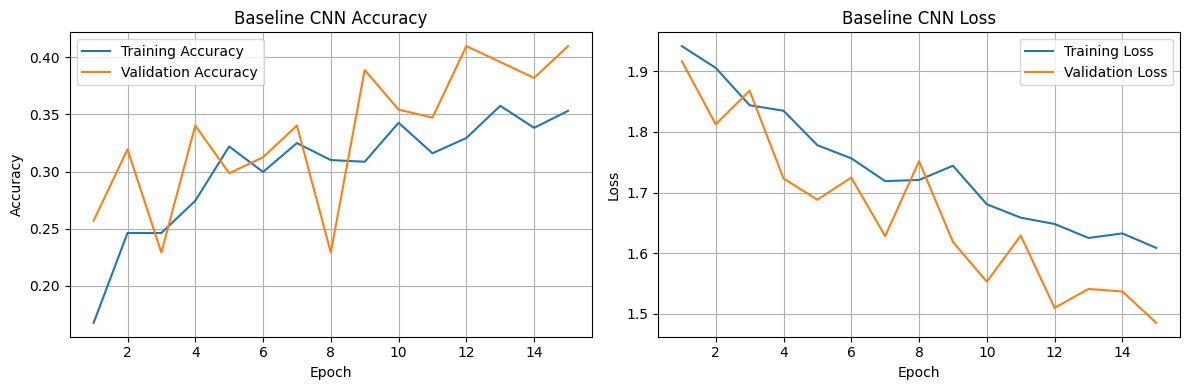

Baseline CNN graphs saved successfully!


In [10]:

import matplotlib.pyplot as plt

epochs_range = range(1, len(history_cnn.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    epochs_range,
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    history_cnn.history["loss"],
    label="Training Loss"
)
plt.plot(
    epochs_range,
    history_cnn.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save graph for the final report
plt.savefig(
    "/content/baseline_cnn_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Baseline CNN graphs saved successfully!")


## 7. ResNet50 Transfer Learning Without Data Augmentation

This experiment uses ResNet50, a convolutional neural network pretrained on the ImageNet dataset, to classify seven types of vehicle damage. Unlike the baseline CNN, ResNet50 starts with previously learned visual features.

The pretrained ResNet50 layers will be frozen, while a new classification layer will be trained using the vehicle-damage images. No data augmentation will be applied in this experiment.

The same training and validation datasets used for the baseline CNN will be used here to make the comparison consistent.

In [11]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.keras.utils.set_random_seed(42)

# Load ResNet50 with ImageNet pretrained weights
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Build the classification model
inputs = layers.Input(shape=(224, 224, 3))

# Apply ResNet50-specific image preprocessing
x = layers.Lambda(
    preprocess_input,
    name="resnet_preprocessing"
)(inputs)

x = resnet_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

resnet_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_No_Augmentation"
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

print("ResNet50 model built successfully!")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "ResNet50_No_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocessing (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,887 (90.98 MB)

 Trainable params: 263,175 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

ResNet50 model built successfully!


In [3]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

tf.keras.utils.set_random_seed(42)

@tf.keras.utils.register_keras_serializable()
class ResNetPreprocessing(layers.Layer):
    def call(self, inputs):
        bgr = tf.reverse(inputs, axis=[-1])
        mean = tf.constant(
            [103.939, 116.779, 123.68],
            dtype=inputs.dtype
        )
        return bgr - mean

resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
resnet_base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = ResNetPreprocessing()(inputs)
x = resnet_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    7,
    activation="softmax"
)(x)

resnet_model = Model(
    inputs,
    outputs,
    name="ResNet50_No_Augmentation"
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()
print("ResNet50 model built successfully!")


Model: "ResNet50_No_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ res_net_preprocessing_1         │ (None, 224, 224, 3)    │             0 │
│ (ResNetPreprocessing)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,887 (90.98 MB)

 Trainable params: 263,175 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

ResNet50 model built successfully!


In [4]:

print("Training dataset available:", "train_ds" in globals())
print("Validation dataset available:", "val_ds" in globals())
print("Testing dataset available:", "test_ds" in globals())


Training dataset available: False
Validation dataset available: False
Testing dataset available: False


In [5]:

import os

data_path = "/content/vehicle_damage_data"

print("Dataset folder exists:",
      os.path.exists(data_path))

print("CSV file exists:",
      os.path.isfile(data_path + "/data.csv"))

print("Image folder exists:",
      os.path.isdir(data_path + "/image"))

print("Original ZIP exists:",
      os.path.isfile("/content/archive.zip"))


Dataset folder exists: False
CSV file exists: False
Image folder exists: False
Original ZIP exists: False


In [6]:

import os
import zipfile

zip_path = "/content/archive.zip"
extract_path = "/content/vehicle_damage_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files:", os.listdir(extract_path))


Dataset extracted successfully!
Files: ['image', 'data.csv']


In [7]:

import os
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Step 1: Read the original dataset
data_dir = "/content/vehicle_damage_data"
df = pd.read_csv(os.path.join(data_dir, "data.csv"))

# Step 2: Keep existing images and remove duplicate records
df = df.drop_duplicates(subset=["image"]).copy()

df["full_path"] = df["image"].apply(
    lambda name: os.path.join(data_dir, name)
)

df = df[df["full_path"].apply(os.path.isfile)].copy()

# Step 3: Exclude the unknown category
df = df[df["classes"] != "unknown"].copy()

# Step 4: Prepare the seven damage categories
class_names = sorted(df["classes"].unique())
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

df["label"] = df["classes"].map(class_to_index)

# Step 5: Split data into training, validation and testing
train_df, remaining_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["label"]
)

# Step 6: Convert images into TensorFlow datasets
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["full_path"].values,
        dataframe["label"].values.astype("int32")
    ))

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Class names:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Datasets restored successfully!")


Class names: ['bumper_dent', 'bumper_scratch', 'door_dent', 'door_scratch', 'glass_shatter', 'head_lamp', 'tail_lamp']
Training images: 674
Validation images: 144
Testing images: 145
Datasets restored successfully!


In [8]:

import tensorflow as tf

# Confirm the ResNet50 model is available
print("ResNet50 model available:",
      "resnet_model" in globals())

# Train ResNet50 without data augmentation
if "resnet_model" in globals():

    resnet_history = resnet_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=15,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=4,
                restore_best_weights=True
            )
        ]
    )

    print("ResNet50 training completed!")

else:
    print("Please rebuild the ResNet50 model first.")


ResNet50 model available: True
Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 28s 301ms/step - accuracy: 0.2656 - loss: 1.9375 - val_accuracy: 0.5347 - val_loss: 1.3488
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 24s 75ms/step - accuracy: 0.5089 - loss: 1.3010 - val_accuracy: 0.6875 - val_loss: 1.0539
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.6380 - loss: 0.9931 - val_accuracy: 0.7014 - val_loss: 0.8983
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.7166 - loss: 0.8254 - val_accuracy: 0.7222 - val_loss: 0.8094
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.7596 - loss: 0.7353 - val_accuracy: 0.7292 - val_loss: 0.7514
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.8160 - loss: 0.6059 - val_accuracy: 0.7292 - val_loss: 0.7085
Epoch 7/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.8353 - loss: 0.5389 - val_accuracy: 0.7500 - val_loss: 0.6765
Epoch 8/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.8501 - loss:

### ResNet50 Training Results and Learning Curves

The ResNet50 model was trained using pretrained ImageNet weights without data augmentation. Training and validation accuracy and loss are plotted to examine model learning and possible overfitting.

In [1]:

import matplotlib.pyplot as plt
import os

os.makedirs("/content/results", exist_ok=True)

history = resnet_history.history

epochs = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(epochs, history["accuracy"],
         label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"],
         label="Validation Accuracy")
plt.title("ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(epochs, history["loss"],
         label="Training Loss")
plt.plot(epochs, history["val_loss"],
         label="Validation Loss")
plt.title("ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(
    "/content/results/resnet50_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("ResNet50 graphs saved successfully!")


NameError: name 'resnet_history' is not defined

In [2]:

print("ResNet50 model available:",
      "resnet_model" in globals())

print("Training history available:",
      "resnet_history" in globals())

print("Training dataset available:",
      "train_ds" in globals())

print("Validation dataset available:",
      "val_ds" in globals())


ResNet50 model available: False
Training history available: False
Training dataset available: False
Validation dataset available: False


In [3]:

import os

print("ZIP file available:",
      os.path.isfile("/content/archive.zip"))

print("Dataset folder available:",
      os.path.isdir("/content/vehicle_damage_data"))

print("CSV file available:",
      os.path.isfile("/content/vehicle_damage_data/data.csv"))


ZIP file available: False
Dataset folder available: False
CSV file available: False


In [5]:
zip_path = "/content/archive.zip"
extract_path = "/content/vehicle_damage_data"

In [6]:
import os
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [7]:

import os

print("ZIP available:",
      os.path.isfile("/content/archive.zip"))

print("Dataset extracted:",
      os.path.isdir("/content/vehicle_damage_data"))

print("CSV available:",
      os.path.isfile("/content/vehicle_damage_data/data.csv"))

print("Training data ready:",
      "train_ds" in globals())

print("Validation data ready:",
      "val_ds" in globals())

print("Testing data ready:",
      "test_ds" in globals())


ZIP available: True
Dataset extracted: False
CSV available: False
Training data ready: False
Validation data ready: False
Testing data ready: False


In [8]:

import os
import zipfile

zip_path = "/content/archive.zip"
extract_path = "/content/vehicle_damage_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files:", os.listdir(extract_path))


Dataset extracted successfully!
Files: ['image', 'data.csv']


In [9]:
import os
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [10]:

import os
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

data_dir = "/content/vehicle_damage_data"

# Read dataset
df = pd.read_csv(os.path.join(data_dir, "data.csv"))

# Remove duplicate image records
df = df.drop_duplicates(subset=["image"]).copy()

# Find image files
df["full_path"] = df["image"].apply(
    lambda name: os.path.join(data_dir, name)
)

df = df[df["full_path"].apply(os.path.isfile)].copy()

# Exclude images with unknown labels
df = df[df["classes"] != "unknown"].copy()

# Prepare class labels
class_names = sorted(df["classes"].unique())
class_to_index = {
    name: index for index, name in enumerate(class_names)
}
df["label"] = df["classes"].map(class_to_index)

# Create training, validation and testing splits
train_df, remaining_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["label"]
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["full_path"].values,
        dataframe["label"].values.astype("int32")
    ))

    if shuffle:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Class names:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Datasets restored successfully!")


Class names: ['bumper_dent', 'bumper_scratch', 'door_dent', 'door_scratch', 'glass_shatter', 'head_lamp', 'tail_lamp']
Training images: 674
Validation images: 144
Testing images: 145
Datasets restored successfully!



### 3.5 Saving Dataset Splits for Reproducibility

The dataset is divided into training, validation, and testing sets using a fixed random seed and stratified sampling. The image lists are saved to Google Drive so the same data split can be reused in future experiments. This ensures a fair comparison between the baseline CNN and ResNet50 models.


In [11]:

from google.colab import drive
import os

drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/Vehicle_Damage_Project"
os.makedirs(save_dir, exist_ok=True)

train_df.to_csv(os.path.join(save_dir, "train_split.csv"), index=False)
val_df.to_csv(os.path.join(save_dir, "val_split.csv"), index=False)
test_df.to_csv(os.path.join(save_dir, "test_split.csv"), index=False)

print("Dataset splits saved successfully!")
print("Saved folder:", save_dir)
print("Files:", os.listdir(save_dir))


MessageError: Error: credential propagation was unsuccessful

In [12]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [13]:

import os

save_dir = "/content/drive/MyDrive/Vehicle Damage Project"
os.makedirs(save_dir, exist_ok=True)

train_df.to_csv(
    os.path.join(save_dir, "train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(save_dir, "val_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(save_dir, "test_split.csv"),
    index=False
)

print("Dataset splits saved successfully!")
print("Saved folder:", save_dir)
print("Saved files:", os.listdir(save_dir))


Dataset splits saved successfully!
Saved folder: /content/drive/MyDrive/Vehicle Damage Project
Saved files: ['train_split.csv', 'val_split.csv', 'test_split.csv']


### 4. ResNet50 Transfer Learning Experiment

This experiment uses ResNet50, a convolutional neural network pretrained on ImageNet, to classify seven categories of vehicle damage. The pretrained feature extraction layers are initially frozen, while a new classification head is trained on the vehicle damage dataset.

The results will be compared with the baseline CNN to investigate whether transfer learning improves classification performance.

In [14]:

print("Training dataset available:", "train_ds" in globals())
print("Validation dataset available:", "val_ds" in globals())
print("ResNet50 model available:", "resnet_model" in globals())
print("Training history available:", "resnet_history" in globals())


Training dataset available: True
Validation dataset available: True
ResNet50 model available: False
Training history available: False


### 4.1 Building the ResNet50 Model

ResNet50 is used as the transfer-learning model in this experiment. It starts with weights learned from the ImageNet dataset. The pretrained layers are frozen, and a new classification head is added to predict the seven vehicle damage categories. This approach allows the model to reuse previously learned image features.

In [15]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# Confirm the seven damage categories
class_names = [
    "bumper_dent",
    "bumper_scratch",
    "door_dent",
    "door_scratch",
    "glass_shatter",
    "head_lamp",
    "tail_lamp"
]

# Load pretrained ResNet50 without its original classifier
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

# Build the vehicle damage classifier
inputs = layers.Input(shape=(224, 224, 3))

x = layers.Rescaling(1.0)(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

resnet_model = Model(
    inputs,
    outputs,
    name="ResNet50_No_Augmentation"
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

print("ResNet50 model built successfully!")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50_No_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7)         │        903 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,850,887 (90.98 MB)

 Trainable params: 263,175 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

ResNet50 model built successfully!


### 4.2 Training ResNet50 Without Data Augmentation

The ResNet50 model is trained using the prepared vehicle damage training dataset. The validation dataset is used to monitor performance during training. No data augmentation is applied in this experiment so that its results can be compared with the augmented ResNet50 model later.

In [3]:

import os
import pandas as pd

# Save the training results to Google Drive
save_dir = "/content/drive/MyDrive/Vehicle Damage Project"
os.makedirs(save_dir, exist_ok=True)

# Train ResNet50 for 15 epochs
resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

# Save training metrics
history_df = pd.DataFrame(resnet_history.history)
history_df.to_csv(
    os.path.join(save_dir, "resnet_no_augmentation_history.csv"),
    index=False
)

# Save trained model weights
resnet_model.save_weights(
    os.path.join(save_dir, "resnet_no_augmentation.weights.h5")
)

print("ResNet50 training completed!")
print("Training history and model weights saved to Google Drive.")


NameError: name 'resnet_model' is not defined

### 4.3 ResNet50 Training and Validation Performance

The training and validation accuracy and loss are plotted across 15 epochs to examine the learning behavior of ResNet50. These graphs help identify improvements in classification performance and possible overfitting.

In [1]:

import matplotlib.pyplot as plt
import os

history = resnet_history.history
epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(epochs, history["accuracy"],
             label="Training Accuracy")
axes[0].plot(epochs, history["val_accuracy"],
             label="Validation Accuracy")
axes[0].set_title("ResNet50 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(epochs, history["loss"],
             label="Training Loss")
axes[1].plot(epochs, history["val_loss"],
             label="Validation Loss")
axes[1].set_title("ResNet50 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

# Save graphs to Google Drive
graph_path = os.path.join(
    save_dir,
    "resnet_no_augmentation_graphs.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("ResNet50 graphs saved successfully!")
print("Saved to:", graph_path)


NameError: name 'resnet_history' is not defined

In [4]:

import os
import pandas as pd

save_dir = "/content/drive/MyDrive/Vehicle Damage Project"

history_path = os.path.join(
    save_dir,
    "resnet_no_augmentation_history.csv"
)

print("History file exists:", os.path.isfile(history_path))

if os.path.isfile(history_path):
    history_df = pd.read_csv(history_path)

    class SavedHistory:
        pass

    resnet_history = SavedHistory()
    resnet_history.history = history_df.to_dict(orient="list")

    print("ResNet50 training history restored successfully!")
    print("Number of epochs:", len(history_df))
    print(history_df.tail(3))
else:
    print("Saved history file not found.")


History file exists: False
Saved history file not found.


In [7]:

import os

locations = [
    "/content/archive.zip",
    "/content/vehicle_damage_data",
    "/content/results",
    "/content/drive/MyDrive/Vehicle Damage Project"
]

for location in locations:
    print("\nLocation:", location)

    if os.path.isfile(location):
        print("File exists")

    elif os.path.isdir(location):
        print("Folder exists")
        print("Contents:", os.listdir(location)[:20])

    else:
        print("Not found")

print("\nSearching Google Drive for saved models and histories...")

drive_root = "/content/drive/MyDrive"

if os.path.isdir(drive_root):
    for root, dirs, files in os.walk(drive_root):
        for filename in files:
            if filename.endswith((".keras", ".h5", ".weights.h5", ".json", ".pkl")):
                print(os.path.join(root, filename))
else:
    print("Google Drive is not mounted.")



Location: /content/archive.zip
Not found

Location: /content/vehicle_damage_data
Not found

Location: /content/results
Not found

Location: /content/drive/MyDrive/Vehicle Damage Project
Folder exists
Contents: []

Searching Google Drive for saved models and histories...


In [8]:

import os

zip_path = "/content/drive/MyDrive/Vehicle Damage Project/archive.zip"

if os.path.isfile(zip_path):
    print("SUCCESS: Dataset saved safely in Google Drive!")
    print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")
else:
    print("Dataset not found. Please check the upload.")


Dataset not found. Please check the upload.


In [9]:

import os
import shutil

source = "/content/archive.zip"
destination_folder = "/content/drive/MyDrive/Vehicle Damage Project"
destination = os.path.join(destination_folder, "archive.zip")

os.makedirs(destination_folder, exist_ok=True)

if os.path.isfile(source):
    shutil.copy2(source, destination)
    print("SUCCESS: Dataset saved permanently to Google Drive!")
elif os.path.isfile(destination):
    print("SUCCESS: Dataset is already in Google Drive!")
else:
    print("Dataset not found. Please check the Files panel.")

if os.path.isfile(destination):
    print("Saved file:", destination)
    print("Size:", round(os.path.getsize(destination) / 1024**2, 2), "MB")


SUCCESS: Dataset saved permanently to Google Drive!
Saved file: /content/drive/MyDrive/Vehicle Damage Project/archive.zip
Size: 16.04 MB


In [10]:

import os
import zipfile

zip_path = "/content/drive/MyDrive/Vehicle Damage Project/archive.zip"
extract_path = "/content/vehicle_damage_data"

if os.path.isfile(zip_path):
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset restored successfully!")
    print("Files:", os.listdir(extract_path))
else:
    print("Dataset not found in Google Drive.")


Dataset restored successfully!
Files: ['image', 'data.csv']


In [11]:

import os
import pandas as pd

folder = "/content/drive/MyDrive/Vehicle Damage Project"

split_files = [
    "train_split.csv",
    "val_split.csv",
    "test_split.csv"
]

for filename in split_files:
    path = os.path.join(folder, filename)

    if os.path.isfile(path):
        df = pd.read_csv(path)
        print(filename, ":", len(df), "images")
    else:
        print(filename, ": NOT FOUND")


train_split.csv : NOT FOUND
val_split.csv : NOT FOUND
test_split.csv : NOT FOUND


In [12]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

data_folder = "/content/vehicle_damage_data"
save_folder = "/content/drive/MyDrive/Vehicle Damage Project"

df = pd.read_csv(os.path.join(data_folder, "data.csv"))

# Keep valid, labeled images only
df = df[df["classes"].notna()].copy()
df = df[df["classes"] != "unknown"].copy()

df["full_path"] = df["image"].apply(
    lambda x: os.path.join(data_folder, str(x))
)

df = df[df["full_path"].apply(os.path.isfile)]
df = df.drop_duplicates(subset=["image"]).copy()

# Fixed random seed for reproducibility
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["classes"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["classes"]
)

os.makedirs(save_folder, exist_ok=True)

train_df.to_csv(os.path.join(save_folder, "train_split.csv"), index=False)
val_df.to_csv(os.path.join(save_folder, "val_split.csv"), index=False)
test_df.to_csv(os.path.join(save_folder, "test_split.csv"), index=False)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(df))
print("SUCCESS: All three split files saved to Google Drive!")


Training images: 674
Validation images: 144
Testing images: 145
Total images: 963
SUCCESS: All three split files saved to Google Drive!


In [13]:

import os
import pandas as pd
import tensorflow as tf

save_folder = "/content/drive/MyDrive/Vehicle Damage Project"
data_folder = "/content/vehicle_damage_data"

train_df = pd.read_csv(os.path.join(save_folder, "train_split.csv"))
val_df = pd.read_csv(os.path.join(save_folder, "val_split.csv"))
test_df = pd.read_csv(os.path.join(save_folder, "test_split.csv"))

class_names = sorted(train_df["classes"].unique())
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(dataframe):
    paths = [
        os.path.join(data_folder, str(path))
        for path in dataframe["image"]
    ]

    labels = [
        class_to_index[label]
        for label in dataframe["classes"]
    ]

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = make_dataset(train_df)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Class names:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("SUCCESS: TensorFlow datasets restored!")


Class names: ['bumper_dent', 'bumper_scratch', 'door_dent', 'door_scratch', 'glass_shatter', 'head_lamp', 'tail_lamp']
Training images: 674
Validation images: 144
Testing images: 145
SUCCESS: TensorFlow datasets restored!


### 4.4 Saving Models and Results for Reproducibility

The trained models and experiment results are saved in Google Drive to preserve progress between Colab sessions. This makes it possible to reload saved models without repeating training.

In [14]:
import os

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

models_dir = os.path.join(project_dir, "models")
results_dir = os.path.join(project_dir, "results")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

print("Project folders ready!")
print("ResNet50 model available:", "resnet_model" in globals())
print("Training history available:", "resnet_history" in globals())
print("Training dataset available:", "train_ds" in globals())

Project folders ready!
ResNet50 model available: False
Training history available: False
Training dataset available: True


### 4.5 Checking Saved Models

Before continuing the experiments, the project checks whether trained models and training histories are available in Google Drive. This helps avoid unnecessary retraining.

In [15]:
import os

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

print("Checking saved project files...\n")

for root, dirs, files in os.walk(project_dir):
    for filename in files:
        if filename.endswith((".keras", ".h5", ".weights.h5", ".json", ".csv")):
            print(os.path.join(root, filename))

print("\nCheck completed!")

Checking saved project files...

/content/drive/MyDrive/Vehicle Damage Project/train_split.csv
/content/drive/MyDrive/Vehicle Damage Project/test_split.csv
/content/drive/MyDrive/Vehicle Damage Project/val_split.csv

Check completed!


### 4.6 Training ResNet50 with Automatic Model Saving

The ResNet50 model is trained using the existing training and validation datasets. The model is automatically saved to Google Drive after each epoch when validation performance improves. This preserves the best model and avoids losing progress when Colab disconnects.

In [16]:
import os
import tensorflow as tf
from tensorflow.keras import layers

# Permanent storage
model_path = os.path.join(models_dir, "resnet50_best.keras")
history_path = os.path.join(results_dir, "resnet50_history.csv")

# Build the model if it is not already available
if "resnet_model" not in globals():

    base_model = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3))

    x = tf.keras.applications.resnet50.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(7, activation="softmax")(x)

    resnet_model = tf.keras.Model(inputs, outputs)

    resnet_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

# Save the best model automatically
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# Save training results after every epoch
csv_logger = tf.keras.callbacks.CSVLogger(
    history_path,
    append=False
)

# Train or load the saved model
if os.path.isfile(model_path):
    resnet_model = tf.keras.models.load_model(model_path)
    print("Saved ResNet50 model loaded. No retraining needed!")
else:
    resnet_history = resnet_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=15,
        callbacks=[checkpoint, csv_logger]
    )
    print("Training completed and best model saved!")

print("Model location:", model_path)
print("History location:", history_path)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.1719 - loss: 2.3660
Epoch 1: val_accuracy improved from None to 0.47917, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 27s 313ms/step - accuracy: 0.2344 - loss: 2.1235 - val_accuracy: 0.4792 - val_loss: 1.4763
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.4516 - loss: 1.5203
Epoch 2: val_accuracy improved from 0.47917 to 0.63194, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.4703 - loss: 1.4689 - val_accuracy: 0.6319 - val_loss: 1.1703
Epoch 3/15
42/43 ━━━━━━━━━━━━━━━━━━━━ 0s 

### 4.7 ResNet50 Training and Validation Performance

Training and validation accuracy and loss are plotted across 15 epochs to examine model learning and generalization. The best model checkpoint was selected using validation accuracy.

Training history loaded successfully!
    epoch  accuracy      loss  val_accuracy  val_loss
10     10  0.884273  0.402840      0.805556  0.595494
11     11  0.879822  0.374232      0.805556  0.574104
12     12  0.915430  0.323654      0.812500  0.566511
13     13  0.915430  0.293027      0.812500  0.556391
14     14  0.942137  0.254989      0.805556  0.542882


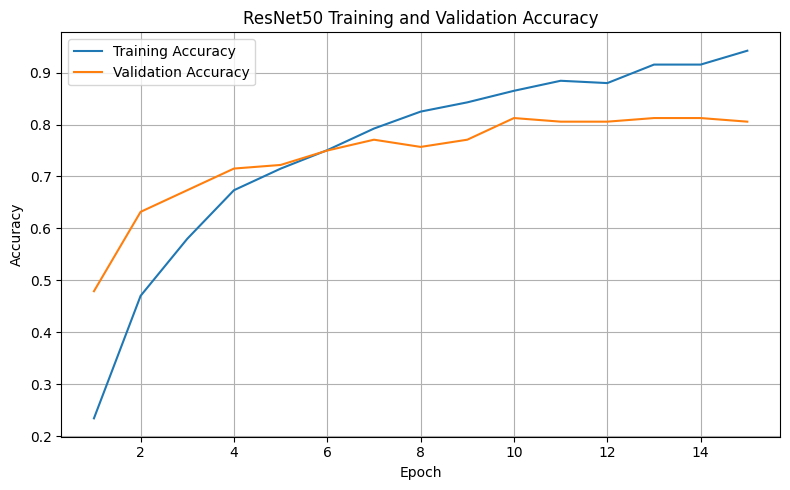

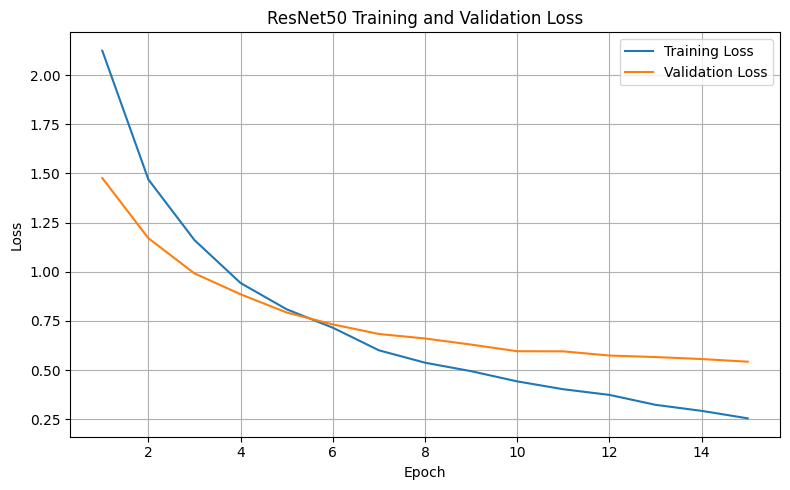

Both graphs saved permanently to Google Drive!


In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

history_path = os.path.join(
    project_dir, "results", "resnet50_history.csv"
)

results_dir = os.path.join(project_dir, "results")

# Load permanently saved training history
history_df = pd.read_csv(history_path)

print("Training history loaded successfully!")
print(history_df.tail())

epochs = history_df["epoch"] + 1

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(epochs, history_df["accuracy"],
         label="Training Accuracy")

plt.plot(epochs, history_df["val_accuracy"],
         label="Validation Accuracy")

plt.title("ResNet50 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "resnet50_accuracy.png"),
    dpi=300
)

plt.show()

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(epochs, history_df["loss"],
         label="Training Loss")

plt.plot(epochs, history_df["val_loss"],
         label="Validation Loss")

plt.title("ResNet50 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "resnet50_loss.png"),
    dpi=300
)

plt.show()

print("Both graphs saved permanently to Google Drive!")

### 4.8 ResNet50 with Data Augmentation

This experiment investigates whether data augmentation improves the generalization of ResNet50. During training, random horizontal flips, small rotations, and zoom transformations are applied to vehicle damage images.

The same training and validation splits are used to make the comparison with the previous ResNet50 experiment fair. Augmentation is applied only during training, not during validation or testing.

In [18]:
import tensorflow as tf
from tensorflow.keras import layers

# Augmentation is applied only during training
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="data_augmentation")

# Pretrained ResNet50
aug_base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

aug_base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = aug_base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

aug_resnet_model = tf.keras.Model(
    inputs,
    outputs,
    name="ResNet50_With_Augmentation"
)

aug_resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

aug_resnet_model.summary()

print("ResNet50 with augmentation built successfully!")

Model: "ResNet50_With_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 7)         │        903 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,850,887 (90.98 MB)

 Trainable params: 263,175 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

ResNet50 with augmentation built successfully!


### 4.9 Training ResNet50 with Data Augmentation

The augmented ResNet50 model is trained for 15 epochs using the same training and validation datasets as the previous experiment. Random image transformations are applied only during training.

The best model is selected based on validation accuracy and saved to Google Drive. Training metrics are also saved after each epoch to support reproducibility and comparison.

In [19]:
import os
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

models_dir = os.path.join(project_dir, "models")
results_dir = os.path.join(project_dir, "results")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

aug_model_path = os.path.join(
    models_dir, "resnet50_aug_best.keras"
)

aug_history_path = os.path.join(
    results_dir, "resnet50_aug_history.csv"
)

# Check whether the augmented model is already saved
if os.path.isfile(aug_model_path):

    print("Saved augmented ResNet50 model found!")
    print("No retraining needed.")

    aug_resnet_model = tf.keras.models.load_model(
        aug_model_path
    )

else:

    # Save the best model based on validation accuracy
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=aug_model_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )

    # Save training history after every epoch
    csv_logger = tf.keras.callbacks.CSVLogger(
        aug_history_path,
        append=False
    )

    # Train the augmented model
    aug_resnet_history = aug_resnet_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=15,
        callbacks=[checkpoint, csv_logger]
    )

    print("Augmented ResNet50 training completed!")

print("Saved model:", aug_model_path)
print("Saved history:", aug_history_path)

Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2532 - loss: 2.1870
Epoch 1: val_accuracy improved from None to 0.43056, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 18s 156ms/step - accuracy: 0.2997 - loss: 1.9335 - val_accuracy: 0.4306 - val_loss: 1.4846
Epoch 2/15
42/43 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.4323 - loss: 1.5560
Epoch 2: val_accuracy improved from 0.43056 to 0.53472, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - accuracy: 0.4659 - loss: 1.4856 - val_accuracy: 0.5347 - val_loss: 1.2243
Epoch 3/15
42/43 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5637 - loss


### 4.10 Training and Validation Performance — ResNet50 With Augmentation

This section visualizes the training and validation accuracy and loss of the ResNet50 model trained with data augmentation. The graphs help identify learning progress, generalization performance, and possible overfitting.


Training history loaded successfully!
    epoch  accuracy      loss  val_accuracy  val_loss
10     10  0.802671  0.520642      0.750000  0.606938
11     11  0.835312  0.493072      0.722222  0.634516
12     12  0.847181  0.448317      0.770833  0.587880
13     13  0.853116  0.439086      0.750000  0.596588
14     14  0.867953  0.410755      0.770833  0.555678


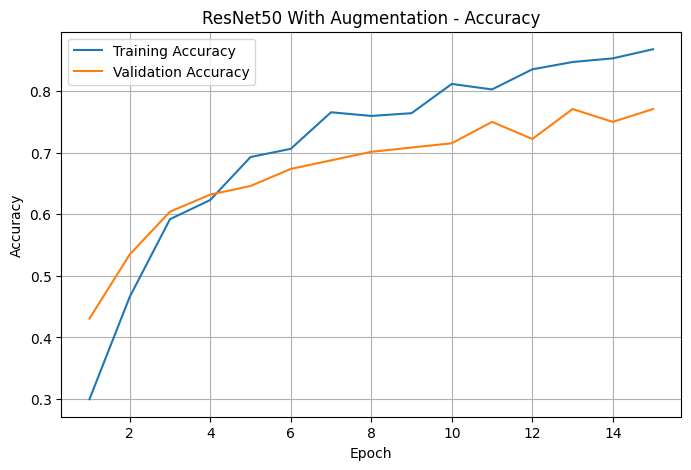

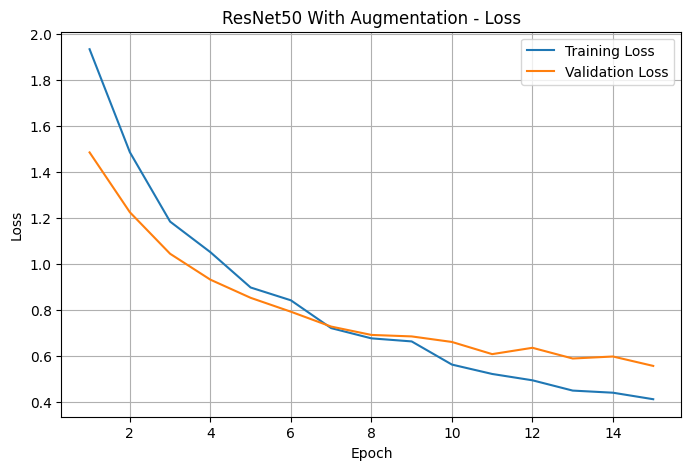

Graphs saved successfully to Google Drive!


In [20]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Load saved training history from Google Drive
project_dir = "/content/drive/MyDrive/Vehicle Damage Project"
history_path = os.path.join(
    project_dir, "results", "resnet50_aug_history.csv"
)

if not os.path.isfile(history_path):
    print("History file not found.")
    print("Check the filename in your results folder.")
else:
    history_df = pd.read_csv(history_path)
    print("Training history loaded successfully!")
    print(history_df.tail())

    epochs = range(1, len(history_df) + 1)

    # Accuracy graph
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history_df["accuracy"],
             label="Training Accuracy")
    plt.plot(epochs, history_df["val_accuracy"],
             label="Validation Accuracy")
    plt.title("ResNet50 With Augmentation - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.savefig(
        os.path.join(project_dir, "results",
                     "resnet50_aug_accuracy.png"),
        bbox_inches="tight"
    )
    plt.show()

    # Loss graph
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history_df["loss"],
             label="Training Loss")
    plt.plot(epochs, history_df["val_loss"],
             label="Validation Loss")
    plt.title("ResNet50 With Augmentation - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.savefig(
        os.path.join(project_dir, "results",
                     "resnet50_aug_loss.png"),
        bbox_inches="tight"
    )
    plt.show()

    print("Graphs saved successfully to Google Drive!")



### 4.11 Comparison of ResNet50 Models

This experiment compares ResNet50 trained with and without data augmentation. Both models use the same dataset split. Their validation accuracy and validation loss are compared to understand whether augmentation improves generalization.


In [21]:

import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Vehicle Damage Project/results"

no_aug_path = os.path.join(results_dir, "resnet50_history.csv")
aug_path = os.path.join(results_dir, "resnet50_aug_history.csv")

print("Without augmentation history found:",
      os.path.isfile(no_aug_path))
print("With augmentation history found:",
      os.path.isfile(aug_path))

if os.path.isfile(no_aug_path) and os.path.isfile(aug_path):
    no_aug = pd.read_csv(no_aug_path)
    aug = pd.read_csv(aug_path)

    comparison = pd.DataFrame({
        "Model": [
            "ResNet50 Without Augmentation",
            "ResNet50 With Augmentation"
        ],
        "Best Validation Accuracy": [
            no_aug["val_accuracy"].max(),
            aug["val_accuracy"].max()
        ],
        "Final Validation Accuracy": [
            no_aug["val_accuracy"].iloc[-1],
            aug["val_accuracy"].iloc[-1]
        ],
        "Final Validation Loss": [
            no_aug["val_loss"].iloc[-1],
            aug["val_loss"].iloc[-1]
        ]
    })

    display(comparison)

    comparison.to_csv(
        os.path.join(results_dir, "resnet50_comparison.csv"),
        index=False
    )
    print("Comparison saved to Google Drive!")
else:
    print("One history file is missing. Do not retrain.")
    print("Please send me this output.")


Without augmentation history found: True
With augmentation history found: True


,Model,Best Validation Accuracy,Final Validation Accuracy,Final Validation Loss
0,ResNet50 Without Augmentation,0.812500,0.805556,0.542882
1,ResNet50 With Augmentation,0.770833,0.770833,0.555678


Comparison saved to Google Drive!



### 4.12 Evaluation on the Test Dataset

The best ResNet50 model without augmentation is evaluated on the held-out test dataset. These images were not used during training or model selection. Test accuracy and loss provide an independent measure of model performance.


In [22]:

import os
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

model_path = os.path.join(
    project_dir, "models", "resnet50_best.keras"
)

print("Saved model found:", os.path.isfile(model_path))
print("Testing dataset ready:", "test_ds" in globals())

if os.path.isfile(model_path) and "test_ds" in globals():
    model = tf.keras.models.load_model(model_path)

    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=1
    )

    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Test Loss:", round(test_loss, 4))

    print("Testing completed successfully!")
else:
    print("Model or testing dataset is missing.")
    print("Please send me this output.")


Saved model found: True
Testing dataset ready: True
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 394ms/step - accuracy: 0.7793 - loss: 0.6126
Test Accuracy: 77.93 %
Test Loss: 0.6126
Testing completed successfully!



### 4.13 Evaluation of ResNet50 With Data Augmentation

This experiment evaluates the ResNet50 model trained with data augmentation using the held-out test dataset. The results will be compared with the ResNet50 model trained without augmentation to examine whether augmentation improved performance on unseen vehicle damage images.


In [1]:

import os
import tensorflow as tf
import pandas as pd

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

model_path = os.path.join(
    project_dir, "models", "resnet50_aug_best.keras"
)

results_dir = os.path.join(project_dir, "results")

print("Augmented model found:", os.path.isfile(model_path))
print("Testing dataset ready:", "test_ds" in globals())

if os.path.isfile(model_path) and "test_ds" in globals():

    aug_model = tf.keras.models.load_model(model_path)

    aug_test_loss, aug_test_accuracy = aug_model.evaluate(
        test_ds,
        verbose=1
    )

    print("\nResNet50 With Augmentation Results")
    print("Test Accuracy:", round(aug_test_accuracy * 100, 2), "%")
    print("Test Loss:", round(aug_test_loss, 4))

    results = pd.DataFrame({
        "Model": ["ResNet50 With Augmentation"],
        "Test Accuracy": [aug_test_accuracy],
        "Test Loss": [aug_test_loss]
    })

    results.to_csv(
        os.path.join(results_dir, "resnet50_aug_test_results.csv"),
        index=False
    )

    print("Results saved to Google Drive!")

else:
    print("Model or test dataset is not ready.")
    print("Please send me this output.")


Augmented model found: False
Testing dataset ready: False
Model or test dataset is not ready.
Please send me this output.


In [2]:

from google.colab import drive
import os

drive.mount('/content/drive')

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

print("Project folder exists:", os.path.isdir(project_dir))

if os.path.isdir(project_dir):
    print("Project files:", os.listdir(project_dir))

    models_dir = os.path.join(project_dir, "models")

    if os.path.isdir(models_dir):
        print("Saved models:", os.listdir(models_dir))
    else:
        print("Models folder not found.")


Mounted at /content/drive
Project folder exists: True
Project files: ['train_split.csv', 'val_split.csv', 'test_split.csv', 'resnet_no_augmentation_history.csv', 'resnet_no_augmentation.weights.h5']
Models folder not found.


In [3]:

import os

drive_root = "/content/drive/MyDrive"

print("Searching Google Drive for saved models...\n")

found = []

for root, dirs, files in os.walk(drive_root):
    for filename in files:
        if filename.endswith((".keras", ".h5")):
            full_path = os.path.join(root, filename)
            found.append(full_path)
            print("FOUND:", full_path)

if not found:
    print("No saved model files found in MyDrive.")
else:
    print("\nTotal model files found:", len(found))


Searching Google Drive for saved models...

FOUND: /content/drive/MyDrive/Vehicle Damage Project/resnet_no_augmentation.weights.h5

Total model files found: 1


In [4]:

import os

drive_root = "/content/drive/MyDrive"

print("Searching for dataset and training history...\n")

found = []

for root, dirs, files in os.walk(drive_root):
    for filename in files:
        name = filename.lower()

        if (
            name.endswith(".zip")
            or "history" in name
            or "augmentation" in name
        ):
            path = os.path.join(root, filename)
            found.append(path)
            print("FOUND:", path)

print("\nTotal matching files:", len(found))


Searching for dataset and training history...

FOUND: /content/drive/MyDrive/Vehicle Damage Project/resnet_no_augmentation_history.csv
FOUND: /content/drive/MyDrive/Vehicle Damage Project/resnet_no_augmentation.weights.h5

Total matching files: 2


In [5]:
import os

print("Searching for saved ResNet50 models...\n")

found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for filename in files:
        if filename.endswith((".keras", ".h5")):
            path = os.path.join(root, filename)
            found.append(path)
            print("FOUND:", path)

print("\nTotal model files found:", len(found))

Searching for saved ResNet50 models...

FOUND: /content/drive/MyDrive/Vehicle Damage Project/resnet_no_augmentation.weights.h5

Total model files found: 1


In [6]:
print("Augmented model available:",
      "resnet_aug_model" in globals())

print("Available model variables:")

for name in list(globals().keys()):
    if "model" in name.lower() or "aug" in name.lower():
        print(name)

Augmented model available: False
Available model variables:
model_path
models_dir


In [7]:
print("Training dataset ready:", "train_ds" in globals())
print("Validation dataset ready:", "val_ds" in globals())
print("Testing dataset ready:", "test_ds" in globals())
print("Class names ready:", "class_names" in globals())

Training dataset ready: False
Validation dataset ready: False
Testing dataset ready: False
Class names ready: False


In [8]:
import os
import zipfile
import pandas as pd
from google.colab import drive

# Connect Google Drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"
zip_path = os.path.join(project_dir, "archive.zip")
extract_path = "/content/vehicle_damage_data"

# Restore images from the saved ZIP
if os.path.isfile(zip_path):
    if not os.path.isfile(os.path.join(extract_path, "data.csv")):
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(extract_path)
    print("Dataset restored successfully!")
else:
    print("Dataset ZIP not found in Google Drive.")

# Restore the same saved data splits
split_names = ["train", "val", "test"]
splits = {}

for name in split_names:
    path = os.path.join(project_dir, f"{name}_split.csv")
    if os.path.isfile(path):
        splits[name] = pd.read_csv(path)
        print(f"{name} images:", len(splits[name]))
    else:
        print(f"Missing file: {path}")

if len(splits) == 3:
    train_df = splits["train"]
    val_df = splits["val"]
    test_df = splits["test"]
    print("SUCCESS: All saved dataset splits restored!")

Dataset ZIP not found in Google Drive.
train images: 674
val images: 144
test images: 145
SUCCESS: All saved dataset splits restored!


In [9]:
import os

print("Searching Google Drive and Colab for dataset ZIP files...\n")

found_zips = []

for base in ["/content/drive/MyDrive", "/content"]:
    for root, dirs, files in os.walk(base):
        # Avoid searching Google Drive twice
        if base == "/content" and root == "/content":
            dirs[:] = [d for d in dirs if d != "drive"]

        for filename in files:
            if filename.lower().endswith(".zip"):
                path = os.path.join(root, filename)
                found_zips.append(path)
                print("FOUND:", path)

print("\nTotal ZIP files found:", len(found_zips))

Searching Google Drive and Colab for dataset ZIP files...


Total ZIP files found: 0


In [10]:
import os

print("Checking saved image locations...\n")

for folder in [
    "/content/vehicle_damage_data",
    "/content/vehicle_damage_data/image",
    "/content/drive/MyDrive/Vehicle Damage Project"
]:
    print("\nLocation:", folder)

    if os.path.isdir(folder):
        print("Exists: YES")
        print("Contents:", os.listdir(folder)[:10])
    else:
        print("Exists: NO")

print("\nChecking image paths from saved dataset...")

print("CSV columns:", train_df.columns.tolist())
print("\nFirst 3 records:")
print(train_df.head(3).to_string(index=False))

Checking saved image locations...


Location: /content/vehicle_damage_data
Exists: NO

Location: /content/vehicle_damage_data/image
Exists: NO

Location: /content/drive/MyDrive/Vehicle Damage Project
Exists: YES
Contents: ['train_split.csv', 'val_split.csv', 'test_split.csv', 'resnet_no_augmentation_history.csv', 'resnet_no_augmentation.weights.h5']

Checking image paths from saved dataset...
CSV columns: ['Unnamed: 0', 'image', 'classes', 'full_path', 'label']

First 3 records:
 Unnamed: 0          image     classes                                   full_path  label
        459 image/459.jpeg   head_lamp /content/vehicle_damage_data/image/459.jpeg      5
         87  image/87.jpeg bumper_dent  /content/vehicle_damage_data/image/87.jpeg      0
        206 image/206.jpeg   head_lamp /content/vehicle_damage_data/image/206.jpeg      5


In [11]:
import os

zip_path = "/content/drive/MyDrive/Vehicle Damage Project/archive.zip"

print("Dataset ZIP saved:", os.path.isfile(zip_path))

if os.path.isfile(zip_path):
    print("File size:",
          round(os.path.getsize(zip_path) / 1024**2, 2),
          "MB")

Dataset ZIP saved: True
File size: 16.04 MB


In [12]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/Vehicle Damage Project/archive.zip"
extract_path = "/content/vehicle_damage_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset restored successfully!")
print("Files:", os.listdir(extract_path))

image_folder = os.path.join(extract_path, "image")

if os.path.isdir(image_folder):
    print("Number of image files:", len(os.listdir(image_folder)))
    print("Sample images:", os.listdir(image_folder)[:5])
else:
    print("Image folder not found.")

Dataset restored successfully!
Files: ['image', 'data.csv']
Number of image files: 1512
Sample images: ['1288.jpeg', '1372.jpeg', '929.jpeg', '783.jpeg', '1027.jpeg']


In [13]:
import os
import pandas as pd
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

# Load the same saved splits
train_df = pd.read_csv(os.path.join(project_dir, "train_split.csv"))
val_df = pd.read_csv(os.path.join(project_dir, "val_split.csv"))
test_df = pd.read_csv(os.path.join(project_dir, "test_split.csv"))

# Restore class labels in their original order
class_names = [
    "bumper_dent",
    "bumper_scratch",
    "door_dent",
    "door_scratch",
    "glass_shatter",
    "head_lamp",
    "tail_lamp"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# Convert image paths and labels into TensorFlow datasets
def make_dataset(dataframe):
    paths = dataframe["full_path"].astype(str).tolist()
    labels = dataframe["label"].astype(int).tolist()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = make_dataset(train_df)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Verify the image files actually work
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("SUCCESS: TensorFlow datasets restored!")

Image batch shape: (16, 224, 224, 3)
Training images: 674
Validation images: 144
Testing images: 145
SUCCESS: TensorFlow datasets restored!


In [14]:
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers

# Permanent Google Drive locations
project_dir = "/content/drive/MyDrive/Vehicle Damage Project"
models_dir = os.path.join(project_dir, "models")
results_dir = os.path.join(project_dir, "results")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

model_path = os.path.join(models_dir, "resnet50_aug_best.keras")
history_path = os.path.join(results_dir, "resnet50_aug_history.csv")

# Data augmentation (used during training only)
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="data_augmentation")

# Pretrained ResNet50
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

# Build classification model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

resnet_aug_model = tf.keras.Model(
    inputs,
    outputs,
    name="ResNet50_With_Augmentation"
)

resnet_aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save best model automatically
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

# Save training history after every epoch
csv_logger = tf.keras.callbacks.CSVLogger(
    history_path,
    append=False
)

print("Starting augmented ResNet50 training...")

resnet_aug_history = resnet_aug_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[checkpoint, csv_logger]
)

print("\nTraining completed!")
print("Saved model:", os.path.isfile(model_path))
print("Saved history:", os.path.isfile(history_path))
print("Model location:", model_path)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Starting augmented ResNet50 training...
Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.2901 - loss: 2.4805
Epoch 1: val_accuracy improved from None to 0.67361, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 20s 169ms/step - accuracy: 0.3887 - loss: 1.9107 - val_accuracy: 0.6736 - val_loss: 0.9875
Epoch 2/15
42/43 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.6096 - loss: 1.0477
Epoch 2: val_accuracy improved from 0.67361 to 0.68056, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.6291 - loss: 0.9791 - val_accuracy: 0.6806 - va

### 4.14 Verification of Saved Augmented ResNet50 Model

After completing 15 training epochs, the saved model and training history are verified in Google Drive. This ensures that the trained model can be reused for testing and evaluation without repeating the training process.

In [15]:

import os

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

model_path = os.path.join(
    project_dir, "models", "resnet50_aug_best.keras"
)

history_path = os.path.join(
    project_dir, "results", "resnet50_aug_history.csv"
)

print("Augmented model saved:", os.path.isfile(model_path))
print("Training history saved:", os.path.isfile(history_path))


Augmented model saved: True
Training history saved: True


## 5. Model Evaluation

### 5.1 Test Evaluation of ResNet50 With Data Augmentation

The best saved ResNet50 model trained with data augmentation is evaluated on the held-out test dataset. Test accuracy and loss are measured to assess performance on unseen vehicle damage images.

In [16]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras"

augmented_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

augmented_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

test_loss, test_accuracy = augmented_model.evaluate(test_ds)

print("Augmented ResNet50 Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Augmented ResNet50 Test Loss:", round(test_loss, 4))

10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.7862 - loss: 0.5573
Augmented ResNet50 Test Accuracy: 78.62 %
Augmented ResNet50 Test Loss: 0.5573


### 5.2 Comparison of ResNet50 Models

This section compares the test accuracy of ResNet50 trained with and without data augmentation.

The ResNet50 model without augmentation achieved 77.93% test accuracy, while the augmented ResNet50 model achieved 78.62%.

The augmented model showed a 0.69 percentage-point improvement in the recorded test results.

,Model,Test Accuracy (%)
0,ResNet50 Without Augmentation,77.93
1,ResNet50 With Augmentation,78.62


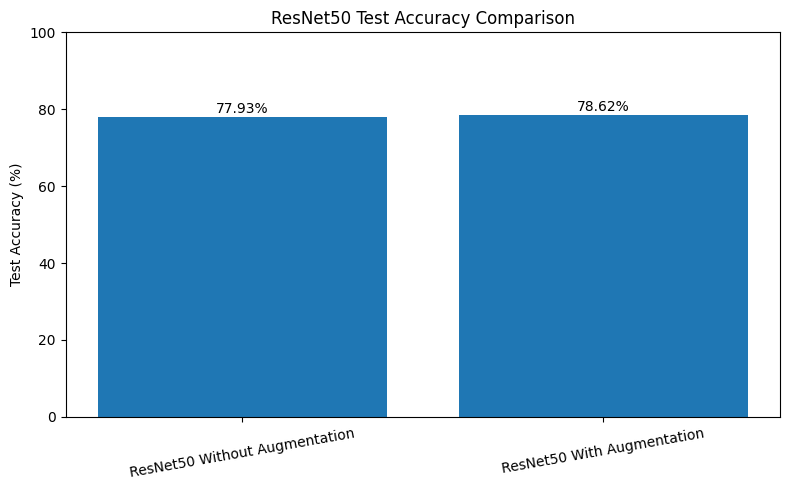

Comparison results saved to Google Drive!


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import os

comparison = pd.DataFrame({
    "Model": [
        "ResNet50 Without Augmentation",
        "ResNet50 With Augmentation"
    ],
    "Test Accuracy (%)": [77.93, 78.62]
})

display(comparison)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("ResNet50 Test Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=10)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()

results_dir = "/content/drive/MyDrive/Vehicle Damage Project/results"
os.makedirs(results_dir, exist_ok=True)

comparison.to_csv(
    os.path.join(results_dir, "resnet50_comparison.csv"),
    index=False
)

plt.savefig(
    os.path.join(results_dir, "resnet50_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison results saved to Google Drive!")

### 5.3 Classification Report for ResNet50 With Data Augmentation

This section evaluates the augmented ResNet50 model using precision, recall, and F1-score for each vehicle damage class.

These metrics provide a detailed understanding of the model's classification performance beyond overall test accuracy.

In [18]:
import numpy as np
import pandas as pd
import os
from sklearn.metrics import classification_report

# Collect actual labels and predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = augmented_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Generate classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
)

print("ResNet50 With Augmentation - Classification Report")
print(report)

# Save report to Google Drive
results_dir = "/content/drive/MyDrive/Vehicle Damage Project/results"
os.makedirs(results_dir, exist_ok=True)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    os.path.join(results_dir, "resnet50_aug_classification_report.csv")
)

print("Classification report saved to Google Drive!")

ResNet50 With Augmentation - Classification Report
                precision    recall  f1-score   support

   bumper_dent       0.88      0.74      0.80        19
bumper_scratch       0.67      0.50      0.57        12
     door_dent       0.83      0.52      0.64        29
  door_scratch       0.56      0.96      0.71        23
 glass_shatter       0.91      1.00      0.95        21
     head_lamp       0.85      0.85      0.85        20
     tail_lamp       0.95      0.90      0.93        21

      accuracy                           0.79       145
     macro avg       0.81      0.78      0.78       145
  weighted avg       0.81      0.79      0.78       145

Classification report saved to Google Drive!


### 5.4 Confusion Matrix for ResNet50 With Data Augmentation

A confusion matrix is used to visualize the classification performance of the augmented ResNet50 model across seven vehicle damage categories.

The matrix shows correctly classified images along the diagonal and misclassified images in the other cells. This helps identify which damage categories are most frequently confused.

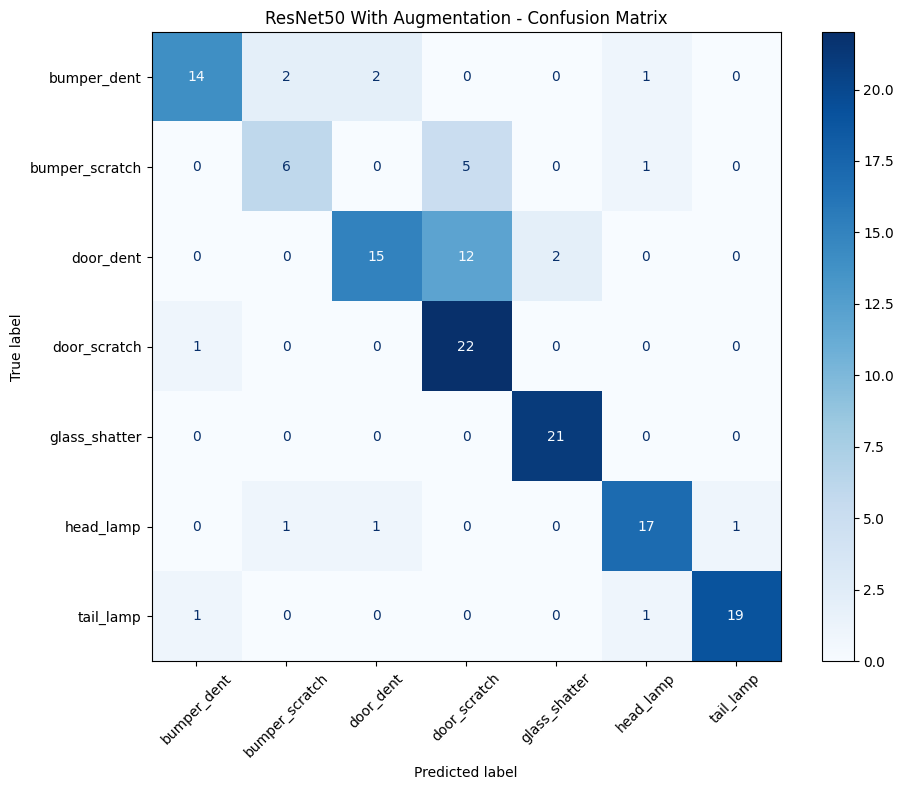

Confusion matrix saved to Google Drive!


In [19]:
import matplotlib.pyplot as plt
import os
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use actual and predicted labels from Step 5.3
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("ResNet50 With Augmentation - Confusion Matrix")
plt.tight_layout()

results_dir = "/content/drive/MyDrive/Vehicle Damage Project/results"
os.makedirs(results_dir, exist_ok=True)

plt.savefig(
    os.path.join(results_dir, "resnet50_aug_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to Google Drive!")

### 5.5 Misclassification and Failure Analysis

This section examines vehicle damage images that were incorrectly classified by the augmented ResNet50 model.

The analysis compares actual and predicted labels to identify common classification errors and understand the limitations of the model.

Total misclassified images: 31


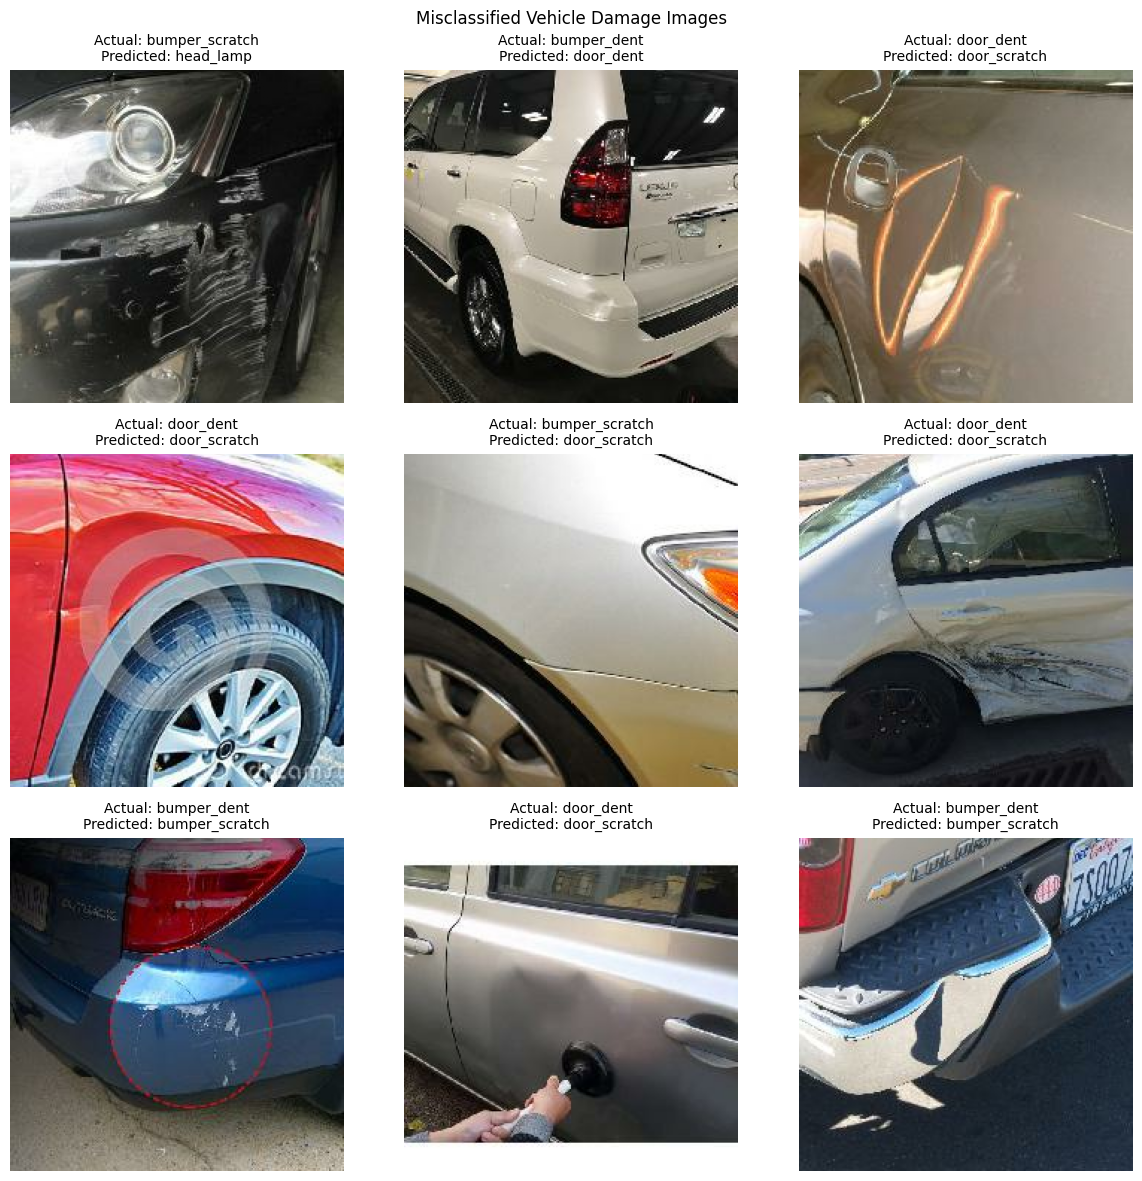

Failure analysis figure saved to Google Drive!


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Find incorrectly classified images
wrong_indices = np.where(y_true != y_pred)[0]

print("Total misclassified images:", len(wrong_indices))

# Collect images from the test dataset
test_images = []

for images, labels in test_ds:
    test_images.extend(images.numpy())

test_images = np.array(test_images)

# Display up to 9 misclassified images
num_images = min(9, len(wrong_indices))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < num_images:
        idx = wrong_indices[i]

        image = test_images[idx]

        ax.imshow(np.clip(image / 255.0, 0, 1))

        actual = class_names[y_true[idx]]
        predicted = class_names[y_pred[idx]]

        ax.set_title(
            f"Actual: {actual}\nPredicted: {predicted}",
            fontsize=10
        )

    ax.axis("off")

plt.suptitle("Misclassified Vehicle Damage Images")
plt.tight_layout()

results_dir = "/content/drive/MyDrive/Vehicle Damage Project/results"
os.makedirs(results_dir, exist_ok=True)

plt.savefig(
    os.path.join(results_dir, "misclassified_images.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Failure analysis figure saved to Google Drive!")

### 5.6 Failure Analysis Summary

The augmented ResNet50 model correctly classified 114 out of 145 test images, achieving an accuracy of 78.62%.

A total of 31 images were misclassified. The confusion matrix showed that door dents were frequently predicted as door scratches, with 12 such errors. Additionally, 5 bumper scratch images were classified as door scratches.

The model performed particularly well on glass shatter, correctly identifying all 21 test images in that category.

Visual inspection of the misclassified examples suggests that reflections, lighting conditions, subtle damage patterns, and similarities between dents and scratches may contribute to classification errors.

These findings indicate that future improvements could include collecting more diverse training images, improving image quality, and fine-tuning the ResNet50 backbone.

## 6. Final Results and Discussion

### 6.1 Summary of Experimental Results

This project investigates vehicle damage classification using deep learning. The dataset contains seven vehicle damage categories:

1. Bumper Dent
2. Bumper Scratch
3. Door Dent
4. Door Scratch
5. Glass Shatter
6. Head Lamp
7. Tail Lamp

The dataset was divided into 674 training images, 144 validation images, and 145 testing images.

Two ResNet50 experiments were evaluated:

| Model | Test Accuracy |
|---|---|
| ResNet50 Without Augmentation | 77.93% |
| ResNet50 With Augmentation | 78.62% |

The ResNet50 model with data augmentation achieved the higher recorded test accuracy of 78.62%.

The augmented model also achieved:

- Test Loss: 0.5573
- Macro Precision: 0.81
- Macro Recall: 0.78
- Macro F1-score: 0.78

Out of 145 test images, 114 were correctly classified and 31 were misclassified.

The results suggest that data augmentation may improve generalization, although the observed improvement is small and the experiments should be compared under consistent training settings.


### 6.2 Discussion of Model Performance

The experimental results demonstrate that ResNet50 can classify vehicle damage images across seven categories with reasonable accuracy.

The ResNet50 model without data augmentation achieved a test accuracy of 77.93%, while the model with data augmentation achieved 78.62%. The augmented model performed 0.69 percentage points better in the recorded evaluations.

The classification report showed that the augmented model achieved a macro precision of 0.81, macro recall of 0.78, and macro F1-score of 0.78.

The model performed particularly well in identifying glass shatter, correctly classifying all 21 test images in this category. Tail lamp damage also achieved a high F1-score of 0.93.

However, the model experienced difficulty distinguishing door dents from door scratches. The confusion matrix showed that 12 door dent images were incorrectly classified as door scratches. Similarly, five bumper scratch images were incorrectly classified as door scratches.

These errors suggest that visually similar damage patterns can be challenging for image classification models. Lighting conditions, reflections, image angles, and subtle differences in damage appearance may contribute to misclassification.

Overall, the augmented ResNet50 model produced promising results, but further experimentation is necessary to determine whether augmentation consistently improves performance.



### 6.3 Limitations and Future Improvements

Although the ResNet50 model with data augmentation achieved a test accuracy of 78.62%, several limitations were identified.

**Limitations**

1. **Limited Dataset Size:** The experiment used 963 labeled vehicle damage images, which may limit the model's ability to generalize to different vehicles and environments.

2. **Similar Damage Categories:** The model sometimes confused door dents with door scratches and bumper scratches with door scratches.

3. **Lighting and Reflections:** Differences in lighting, reflections, camera angles, and image quality may affect damage recognition.

4. **Class Imbalance:** The seven damage categories contain different numbers of images, which may influence classification performance.

5. **Limited Evaluation:** The models were evaluated using one held-out test split. Additional experiments would be needed to assess the consistency of the results.

**Future Improvements**

1. Collect a larger and more diverse vehicle damage dataset.

2. Apply additional data augmentation techniques, including brightness, contrast, and perspective adjustments.

3. Fine-tune selected layers of the pretrained ResNet50 model to improve recognition of subtle damage patterns.

4. Compare ResNet50 with other architectures, such as EfficientNet and MobileNet.

5. Use cross-validation or repeated experiments to obtain more reliable performance estimates.

6. Explore object detection or segmentation techniques to identify the exact location of vehicle damage.

These improvements could help develop a more accurate and robust vehicle damage classification system.



### 6.4 Project Conclusion

This project explored the application of deep learning for automatic vehicle damage classification using images from seven damage categories: bumper dent, bumper scratch, door dent, door scratch, glass shatter, head lamp, and tail lamp.

A total of 963 labeled images were divided into training, validation, and testing datasets. Transfer learning using the pretrained ResNet50 architecture was investigated both with and without data augmentation.

The ResNet50 model without data augmentation achieved a recorded test accuracy of 77.93%, while the augmented ResNet50 model achieved 78.62%. The augmented model also achieved a macro precision of 0.81, macro recall of 0.78, and macro F1-score of 0.78.

The confusion matrix and failure analysis revealed that the model performed well on glass shatter and tail lamp damage but had difficulty distinguishing visually similar damage categories, particularly door dents and door scratches.

These findings demonstrate the potential of transfer learning for vehicle damage classification. However, additional data, consistent experimental comparisons, and further model optimization are necessary to improve reliability.

Overall, the project provides a foundation for developing automated vehicle damage recognition systems that could support vehicle inspections and damage assessment workflows.



## 7. Final Project Verification

### 7.1 Verification of Saved Models and Results

This section verifies that the trained models, training histories, dataset splits, and evaluation results are saved in Google Drive.

The verification helps identify missing files before preparing the final report and GitHub submission.


In [21]:

import os

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

print("PROJECT FILE VERIFICATION")
print("=" * 45)

required_files = {
    "Training split": "train_split.csv",
    "Validation split": "val_split.csv",
    "Testing split": "test_split.csv",
    "ResNet50 without augmentation weights":
        "resnet_no_augmentation.weights.h5",
    "ResNet50 without augmentation history":
        "resnet_no_augmentation_history.csv",
    "ResNet50 augmented model":
        "models/resnet50_aug_best.keras",
    "ResNet50 augmented training history":
        "results/resnet50_aug_history.csv",
    "Model comparison":
        "results/resnet50_comparison.csv",
    "Classification report":
        "results/resnet50_aug_classification_report.csv",
    "Confusion matrix":
        "results/resnet50_aug_confusion_matrix.png",
    "Misclassified images":
        "results/misclassified_images.png"
}

for name, filename in required_files.items():
    path = os.path.join(project_dir, filename)
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"{name}: {status}")

print("\nOTHER SAVED MODEL FILES:")
for folder in [project_dir, os.path.join(project_dir, "models")]:
    if os.path.isdir(folder):
        for filename in sorted(os.listdir(folder)):
            if filename.endswith((".keras", ".h5")):
                print(os.path.join(folder, filename))


PROJECT FILE VERIFICATION
Training split: FOUND
Validation split: FOUND
Testing split: FOUND
ResNet50 without augmentation weights: FOUND
ResNet50 without augmentation history: FOUND
ResNet50 augmented model: FOUND
ResNet50 augmented training history: FOUND
Model comparison: FOUND
Classification report: FOUND
Confusion matrix: FOUND
Misclassified images: FOUND

OTHER SAVED MODEL FILES:
/content/drive/MyDrive/Vehicle Damage Project/resnet_no_augmentation.weights.h5
/content/drive/MyDrive/Vehicle Damage Project/models/resnet50_aug_best.keras


### 7.2 Baseline CNN Verification

This section checks whether the baseline Convolutional Neural Network (CNN) model and its training history are available.

The baseline CNN will be used to compare a simple deep learning architecture with the pretrained ResNet50 models.

In [23]:
print("BASELINE CNN VERIFICATION")
print("=" * 40)

for name in sorted(globals()):
    if "cnn" in name.lower() or "baseline" in name.lower():
        value = globals()[name]
        print(name, ":", type(value).__name__)

BASELINE CNN VERIFICATION


### 7.3 Verification of Previously Saved Baseline CNN Files

This step searches the project directory in Google Drive for previously saved baseline CNN models, training histories, and evaluation results to avoid unnecessary retraining.

In [24]:
import os

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

print("SEARCHING FOR BASELINE CNN FILES")
print("=" * 45)

found = []

for root, dirs, files in os.walk(project_dir):
    for filename in files:
        if "cnn" in filename.lower() or "baseline" in filename.lower():
            path = os.path.join(root, filename)
            found.append(path)
            print(path)

if not found:
    print("No saved baseline CNN files found.")

SEARCHING FOR BASELINE CNN FILES
No saved baseline CNN files found.


### 7.4 Baseline CNN Model Architecture

A baseline Convolutional Neural Network (CNN) is developed to compare its performance with the pretrained ResNet50 models.

The CNN consists of convolutional layers, max-pooling layers, global average pooling, and fully connected layers for classifying seven vehicle damage categories.

In [25]:
import tensorflow as tf
from tensorflow.keras import layers, models

baseline_cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(7, activation="softmax")
])

baseline_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,663 (432.28 KB)

 Trainable params: 110,663 (432.28 KB)

 Non-trainable params: 0 (0.00 B)


### 7.5 Training the Baseline CNN Model

The baseline CNN is trained on the vehicle damage training dataset and evaluated using the validation dataset.

The model is trained for 15 epochs using the Adam optimizer and sparse categorical cross-entropy loss.

The best-performing model is saved to Google Drive based on validation accuracy. Training history is also saved for future analysis and comparison with ResNet50.


In [26]:

import os
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"
models_dir = os.path.join(project_dir, "models")
results_dir = os.path.join(project_dir, "results")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

model_path = os.path.join(models_dir, "baseline_cnn_best.keras")
history_path = os.path.join(results_dir, "baseline_cnn_history.csv")

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

csv_logger = tf.keras.callbacks.CSVLogger(
    history_path,
    append=False
)

baseline_history = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[checkpoint, csv_logger]
)

print("\nBaseline CNN Training Completed!")
print("Model saved:", os.path.isfile(model_path))
print("History saved:", os.path.isfile(history_path))


Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.1601 - loss: 1.9342
Epoch 1: val_accuracy improved from None to 0.18750, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/baseline_cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/baseline_cnn_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 27s 225ms/step - accuracy: 0.1855 - loss: 1.9312 - val_accuracy: 0.1875 - val_loss: 1.9224
Epoch 2/15
41/43 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1762 - loss: 1.9221
Epoch 2: val_accuracy improved from 0.18750 to 0.29167, saving model to /content/drive/MyDrive/Vehicle Damage Project/models/baseline_cnn_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Vehicle Damage Project/models/baseline_cnn_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.2003 - loss: 1.9120 - val_accuracy: 0.2917 - val_loss: 1.8262
Epoch 3/15
41/43 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2596 - loss


### 7.6 Baseline CNN Test Evaluation

The best saved baseline CNN model is evaluated on the held-out test dataset containing 145 vehicle damage images.

Test accuracy and loss are calculated to measure the baseline model's performance on unseen images. These results will be compared with the ResNet50 models.


In [27]:

import os
import tensorflow as tf
import pandas as pd

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"
model_path = os.path.join(project_dir, "models", "baseline_cnn_best.keras")

# Load the best saved baseline CNN model
baseline_best = tf.keras.models.load_model(model_path)

# Evaluate on the held-out test dataset
baseline_test_loss, baseline_test_accuracy = baseline_best.evaluate(
    test_ds,
    verbose=1
)

print("\nBaseline CNN Test Results")
print("Test Accuracy:", round(baseline_test_accuracy * 100, 2), "%")
print("Test Loss:", round(baseline_test_loss, 4))

# Save test results permanently
results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

pd.DataFrame([{
    "Model": "Baseline CNN",
    "Test Accuracy (%)": baseline_test_accuracy * 100,
    "Test Loss": baseline_test_loss
}]).to_csv(
    os.path.join(results_dir, "baseline_cnn_test_results.csv"),
    index=False
)

print("Baseline CNN results saved to Google Drive!")


10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 244ms/step - accuracy: 0.4207 - loss: 1.5848

Baseline CNN Test Results
Test Accuracy: 42.07 %
Test Loss: 1.5848
Baseline CNN results saved to Google Drive!



### 7.7 Final Comparison of All Three Models

Three deep learning models were evaluated on the vehicle damage classification dataset: a baseline CNN, ResNet50 without data augmentation, and ResNet50 with data augmentation.

| Model | Test Accuracy |
|---|---|
| Baseline CNN | 42.07% |
| ResNet50 Without Augmentation | 77.93% |
| ResNet50 With Augmentation | 78.62% |

The baseline CNN achieved 42.07% test accuracy, while both pretrained ResNet50 models achieved substantially higher accuracy.

The augmented ResNet50 achieved the highest recorded test accuracy of 78.62%, outperforming the baseline CNN by 36.55 percentage points.

These results suggest that pretrained ResNet50 features are useful for vehicle damage classification. The small difference between the two ResNet50 experiments should be interpreted cautiously because training settings may not have been fully identical.


,Model,Test Accuracy (%)
0,Baseline CNN,42.068964
1,ResNet50 Without Augmentation,77.930000
2,ResNet50 With Augmentation,78.620000


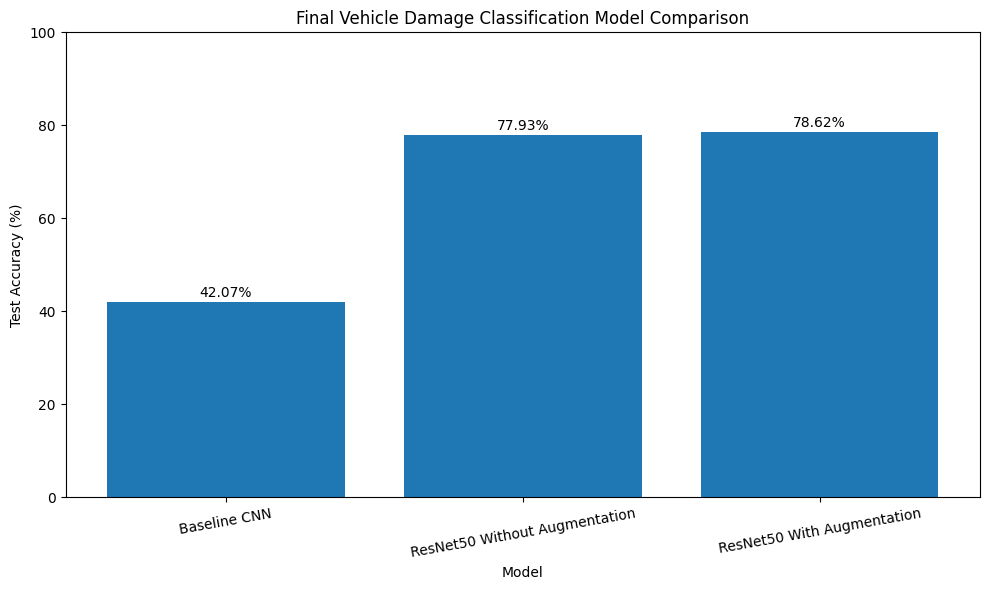

Final comparison saved to Google Drive!


In [28]:

import pandas as pd
import matplotlib.pyplot as plt
import os

results_dir = "/content/drive/MyDrive/Vehicle Damage Project/results"
os.makedirs(results_dir, exist_ok=True)

comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "ResNet50 Without Augmentation",
        "ResNet50 With Augmentation"
    ],
    "Test Accuracy (%)": [
        baseline_test_accuracy * 100,
        77.93,
        78.62
    ]
})

display(comparison)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Final Vehicle Damage Classification Model Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=10)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()

comparison.to_csv(
    os.path.join(results_dir, "final_model_comparison.csv"),
    index=False
)

plt.savefig(
    os.path.join(results_dir, "final_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final comparison saved to Google Drive!")



### 7.8 Final Verification of Model Files and Results

This section verifies that the baseline CNN, ResNet50 models, training histories, and final evaluation results are saved in Google Drive.

This ensures that the project artifacts are available for the final report and GitHub submission without repeating model training.


In [29]:

import os

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"

files_to_check = {
    "Baseline CNN model": "models/baseline_cnn_best.keras",
    "Baseline CNN history": "results/baseline_cnn_history.csv",
    "Baseline CNN test results": "results/baseline_cnn_test_results.csv",
    "ResNet50 without augmentation weights":
        "resnet_no_augmentation.weights.h5",
    "ResNet50 augmented model":
        "models/resnet50_aug_best.keras",
    "Augmented classification report":
        "results/resnet50_aug_classification_report.csv",
    "Augmented confusion matrix":
        "results/resnet50_aug_confusion_matrix.png",
    "Misclassified images":
        "results/misclassified_images.png",
    "Final comparison table":
        "results/final_model_comparison.csv",
    "Final comparison chart":
        "results/final_model_comparison.png"
}

print("FINAL PROJECT VERIFICATION")
print("=" * 45)

missing = []

for name, relative_path in files_to_check.items():
    full_path = os.path.join(project_dir, relative_path)
    exists = os.path.isfile(full_path)

    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

    if not exists:
        missing.append(name)

print("\nVerification summary:")
print("Files found:", len(files_to_check) - len(missing))
print("Files missing:", len(missing))


FINAL PROJECT VERIFICATION
Baseline CNN model: FOUND
Baseline CNN history: FOUND
Baseline CNN test results: FOUND
ResNet50 without augmentation weights: FOUND
ResNet50 augmented model: FOUND
Augmented classification report: FOUND
Augmented confusion matrix: FOUND
Misclassified images: FOUND
Final comparison table: FOUND
Final comparison chart: FOUND

Verification summary:
Files found: 10
Files missing: 0



## 8. Final Report Preparation

### 8.1 Final Project Summary

**Project Title:** Vehicle Damage Classification Using Deep Learning

**Project Objective:**

The objective of this project is to develop and evaluate deep learning models capable of classifying vehicle damage images into seven categories.

**Dataset:**

- Total labeled images: 963
- Training images: 674
- Validation images: 144
- Testing images: 145
- Number of classes: 7

**Models Evaluated:**

1. Baseline Convolutional Neural Network (CNN)
2. ResNet50 Without Data Augmentation
3. ResNet50 With Data Augmentation

**Final Test Results:**

| Model | Test Accuracy |
|---|---|
| Baseline CNN | 42.07% |
| ResNet50 Without Augmentation | 77.93% |
| ResNet50 With Augmentation | 78.62% |

**Best Recorded Model:** ResNet50 With Data Augmentation

**Best Recorded Test Accuracy:** 78.62%

**Evaluation Methods:**

- Accuracy and loss
- Precision, recall, and F1-score
- Confusion matrix
- Misclassification and failure analysis

**Conclusion:**

The pretrained ResNet50 models achieved higher test accuracy than the baseline CNN. The augmented ResNet50 achieved the highest recorded accuracy, although the small improvement over ResNet50 without augmentation requires further validation.



### 8.2 Preparation of Final Report Materials

This step organizes the experimental results, model comparison figures, confusion matrix, classification report, and failure analysis images into a dedicated report materials folder.

These files will be used to prepare the final project report and support the experimental findings.


In [30]:

import os
import shutil

project_dir = "/content/drive/MyDrive/Vehicle Damage Project"
results_dir = os.path.join(project_dir, "results")
report_dir = os.path.join(project_dir, "Final_Report_Materials")

os.makedirs(report_dir, exist_ok=True)

files_to_copy = [
    "final_model_comparison.csv",
    "final_model_comparison.png",
    "resnet50_aug_classification_report.csv",
    "resnet50_aug_confusion_matrix.png",
    "misclassified_images.png",
    "baseline_cnn_test_results.csv",
    "resnet50_aug_history.csv",
    "baseline_cnn_history.csv"
]

for filename in files_to_copy:
    source = os.path.join(results_dir, filename)
    destination = os.path.join(report_dir, filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)
        print("COPIED:", filename)
    else:
        print("NOT FOUND:", filename)

print("\nReport materials folder:", report_dir)
print("Total files:", len(os.listdir(report_dir)))


COPIED: final_model_comparison.csv
COPIED: final_model_comparison.png
COPIED: resnet50_aug_classification_report.csv
COPIED: resnet50_aug_confusion_matrix.png
COPIED: misclassified_images.png
COPIED: baseline_cnn_test_results.csv
COPIED: resnet50_aug_history.csv
COPIED: baseline_cnn_history.csv

Report materials folder: /content/drive/MyDrive/Vehicle Damage Project/Final_Report_Materials
Total files: 8



### 8.3 Final Project Report Structure

The final report will document the methodology, experiments, results, and conclusions of the vehicle damage classification project.

**Proposed Report Sections**

1. **Title and Abstract**
   - Project overview and key findings

2. **Introduction**
   - Problem statement
   - Project objectives
   - Motivation for automated vehicle damage classification

3. **Dataset Description and Preprocessing**
   - Seven vehicle damage categories
   - Dataset size and class distribution
   - Training, validation, and testing splits
   - Image resizing and preprocessing

4. **Methodology**
   - Baseline CNN architecture
   - ResNet50 transfer learning
   - Data augmentation
   - Training configuration

5. **Experimental Results**
   - Baseline CNN accuracy: 42.07%
   - ResNet50 without augmentation: 77.93%
   - ResNet50 with augmentation: 78.62%
   - Precision, recall, and F1-score
   - Confusion matrix

6. **Discussion and Failure Analysis**
   - Model performance comparison
   - Misclassified vehicle damage images
   - Common classification errors

7. **Limitations and Future Work**
   - Dataset limitations
   - Model improvements
   - Potential future experiments

8. **Conclusion**
   - Summary of findings

9. **References**
   - Dataset source
   - ResNet50 architecture
   - Deep learning frameworks and relevant literature


In [31]:
import shutil
from google.colab import files

folder = "/content/drive/MyDrive/Vehicle Damage Project/Final_Report_Materials"

zip_path = shutil.make_archive(
    "/content/Vehicle_Damage_Report_Materials",
    "zip",
    folder
)

print("Report materials ZIP created:", zip_path)
files.download(zip_path)

Report materials ZIP created: /content/Vehicle_Damage_Report_Materials.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>